# 05 - Transformer Encoder for Log Anomaly Detection

โมเดลนี้เป็น **Transformer Encoder แบบ supervised ระดับ session** อ่าน `Sequence` ของ HDFS ทั้ง session แล้วทำนายว่าเป็น Normal (0) หรือ Anomaly (1)
จุดเด่นที่ LSTM ไม่มีคือ **Attention weights** ซึ่งบอกได้ว่าโมเดล "ดู" event ไหนตอนตัดสินใจ ใช้เป็นคำอธิบายให้ SOC analyst ได้

ขั้นตอน: โหลดข้อมูล -> สร้าง vocabulary (+ `<CLS>`) -> padding mask -> สร้างโมเดล -> train -> เลือก threshold -> ประเมิน test -> Attention heatmap

## 0. แนวคิด: ทำไมต้อง Transformer?

### LSTM อ่านแบบ "ทีละบรรทัด"
LSTM อ่าน log ทีละ event จากซ้ายไปขวา แล้วสรุปทุกอย่างไว้ใน hidden state เหมือน analyst ที่อ่าน log ทีละบรรทัดแล้ว**จดโน้ตสั้นๆ ในหัว**
ถ้า session ยาว ข้อมูลช่วงต้นจะค่อยๆ เลือนหายไป และเราไม่รู้ว่าโมเดลจำอะไรไว้บ้าง (black box)

### Transformer อ่านแบบ "กาง log ทั้งหมดบนโต๊ะ"
**Self-Attention** ให้ทุก event มองเห็นทุก event อื่นในครั้งเดียว แล้วถามว่า "event ไหนเกี่ยวกับฉันมากที่สุด?"
เหมือน **SIEM correlation rule**: เห็น `E5 (receiving block)` แล้วไปหาว่ามี `E4 (received block)` ตามมาหรือไม่ ไม่ว่าจะห่างกันกี่บรรทัด

| แนวคิด | เปรียบเทียบกับงาน SOC |
|---|---|
| **Query (Q)** | คำถามที่ event นี้ถาม เช่น "ใครคือคู่ของฉัน?" |
| **Key (K)** | ป้ายชื่อ/tag ของแต่ละ event ที่ไว้ให้คนอื่นค้นหา |
| **Value (V)** | เนื้อหาจริงที่ส่งต่อเมื่อถูกเลือก |
| **Attention weight** | คะแนนความเกี่ยวข้อง (รวมกันได้ 1) คล้าย correlation score |
| **Multi-head** | analyst หลายคนดูคนละมุม: คนหนึ่งดูลำดับเวลา อีกคนดู event ที่ error |
| **Positional Encoding** | เลขบรรทัด: attention ไม่รู้ลำดับเอง ต้องบอกว่า event ไหนมาก่อน-หลัง |
| **`<CLS>` token** | "หัวหน้ากะ" ที่อ่านสรุปทั้ง session แล้วออก verdict เพียงตัวเดียว |
| **Padding mask** | บอกโมเดลว่าช่องว่างที่เติมไว้ (`<PAD>`) ไม่ใช่ log จริง ห้ามสนใจ |

สูตรหลัก: $\text{Attention}(Q,K,V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$

> ข้อจำกัด: Attention คำนวณทุกคู่ event = $O(L^2)$ จึงต้องกำหนดความยาวสูงสุด (`MAX_LEN`)

## 1. Import libraries และตั้งค่า

In [1]:
from pathlib import Path
import json
import math
import random
import time
from datetime import datetime
from typing import Dict, Iterable, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score)
from torch import nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset

SEED = 42
BATCH_SIZE = 256
MAX_LEN = 64            # ครอบคลุม 99.99% ของ session (99.9th percentile = 41 events)
PAD_ID, UNK_ID, CLS_ID = 0, 1, 2

DATA_DIR = Path("..") / "data" / "processed" / "HDFS"
RESULT_DIR = Path("..") / "results" / "metrics"
FIGURE_DIR = Path("..") / "results" / "figures"
CHECKPOINT_DIR = Path("..") / "checkpoints"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed: int = SEED) -> None:
    """Set reproducible random seeds for Python, NumPy, and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print(f"[1] Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

[1] Device: cpu


## 2. โหลดและตรวจสอบข้อมูล

ใช้ split เดียวกับ Week 3-4 (70/15/15 stratified) เพื่อให้เปรียบเทียบโมเดลได้อย่างยุติธรรม

In [2]:
def load_dataset(path: Path) -> pd.DataFrame:
    """Load one processed HDFS split and validate its columns and labels."""
    if not path.is_file():
        raise FileNotFoundError(f"ไม่พบไฟล์: {path}")
    frame = pd.read_csv(path)
    missing = {"BlockId", "Sequence", "Label"}.difference(frame.columns)
    if missing:
        raise ValueError(f"{path.name} ขาด columns: {sorted(missing)}")
    if not set(frame["Label"].unique()).issubset({0, 1}):
        raise ValueError(f"{path.name}: Label ต้องเป็น 0 หรือ 1")
    return frame

train = load_dataset(DATA_DIR / "train.csv")
validation = load_dataset(DATA_DIR / "val.csv")
test = load_dataset(DATA_DIR / "test.csv")

# ตรวจว่าไฟล์ครบ (กันกรณีอัปโหลดไฟล์ขึ้น Colab ยังไม่เสร็จแล้วกดรัน -> อ่านได้แค่ครึ่งไฟล์โดยไม่มี error)
EXPECTED_ROWS = {"train": 402_542, "validation": 86_259, "test": 86_260}
for split_name, split_frame in (("train", train), ("validation", validation), ("test", test)):
    if len(split_frame) != EXPECTED_ROWS[split_name]:
        raise ValueError(f"{split_name}.csv มี {len(split_frame):,} แถว แต่ควรมี {EXPECTED_ROWS[split_name]:,} "
                         f"-> ไฟล์อาจอัปโหลดไม่ครบ ให้อัปโหลดใหม่แล้วรันอีกครั้ง")
print("✅ จำนวนแถวของ train/validation/test ครบถ้วน")
for name, frame in (("train", train), ("validation", validation), ("test", test)):
    print(f"{name:>10}: {len(frame):,} sessions | Anomaly={frame.Label.mean():.2%}")

✅ จำนวนแถวของ train/validation/test ครบถ้วน
     train: 402,542 sessions | Anomaly=2.93%
validation: 86,259 sessions | Anomaly=2.93%
      test: 86,260 sessions | Anomaly=2.93%


## 3. ความยาว session และการเลือก `MAX_LEN`

เพราะ attention ใช้หน่วยความจำ $O(L^2)$ เราจึงตัด session ที่ยาวเกิน `MAX_LEN` (เก็บ event แรกๆ ไว้)
ตรวจดูว่าการตัดนี้กระทบข้อมูลน้อยมาก

count    402542.0
mean         19.4
std           5.2
min           2.0
50%          19.0
90%          25.0
99%          32.0
99.9%        41.0
max         298.0
Name: Sequence, dtype: float64

Sessions longer than MAX_LEN=64: 34 (0.0084%)


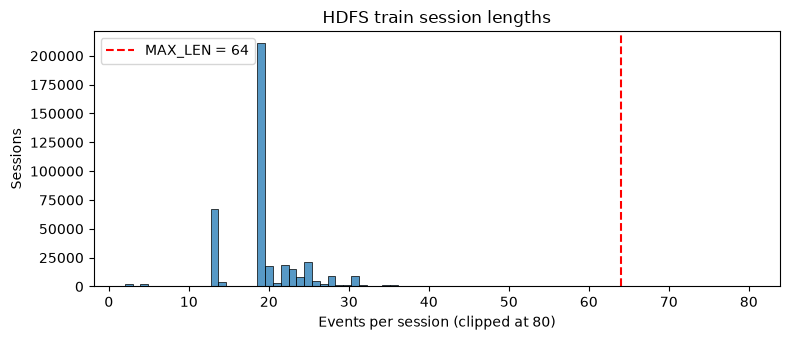

In [3]:
lengths = train["Sequence"].str.split().str.len()
print(lengths.describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(1))
print(f"\nSessions longer than MAX_LEN={MAX_LEN}: {(lengths > MAX_LEN).sum():,} "
      f"({(lengths > MAX_LEN).mean():.4%})")

plt.figure(figsize=(8, 3.5))
sns.histplot(lengths.clip(upper=80), bins=80)
plt.axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.xlabel("Events per session (clipped at 80)")
plt.ylabel("Sessions")
plt.title("HDFS train session lengths")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Vocabulary และ encoding

เหมือน Week 4 แต่เพิ่ม token พิเศษ `<CLS>` ไว้**หน้าสุด**ของทุก session:
- `<PAD>`=0: ช่องว่างที่เติมให้ทุก session ใน batch ยาวเท่ากัน
- `<UNK>`=1: event ที่ไม่เคยเห็นตอน train (เหมือน signature ที่ไม่อยู่ใน rule set)
- `<CLS>`=2: "หัวหน้ากะ" ตำแหน่งที่โมเดลใช้สรุปผลทั้ง session

ตัวอย่าง: `E5 E22 E5` -> `[<CLS>, E5, E22, E5]` -> `[2, 7, 19, 7]`

In [4]:
def create_vocabulary(frames: Iterable[pd.DataFrame]) -> Tuple[Dict[str, int], Dict[int, str]]:
    """Build event vocabulary from training data with PAD=0, UNK=1, CLS=2."""
    events = sorted({event for frame in frames for sequence in frame["Sequence"]
                     for event in str(sequence).split()})
    event_to_id = {"<PAD>": PAD_ID, "<UNK>": UNK_ID, "<CLS>": CLS_ID}
    event_to_id.update({event: index for index, event in enumerate(events, start=3)})
    return event_to_id, {index: event for event, index in event_to_id.items()}

def encode_session(sequence: str, event_to_id: Dict[str, int], max_len: int = MAX_LEN) -> List[int]:
    """Encode a session as [CLS] + event ids, truncated to max_len events."""
    ids = [event_to_id.get(event, UNK_ID) for event in str(sequence).split()[:max_len]]
    return [CLS_ID] + ids

event_to_id, id_to_event = create_vocabulary((train,))
print(f"[4] Vocabulary size: {len(event_to_id)} (45 templates + 3 special tokens)")
example = train["Sequence"].iloc[0]
print(f"Raw:     {example}")
print(f"Encoded: {encode_session(example, event_to_id)}")

[4] Vocabulary size: 48 (45 templates + 3 special tokens)
Raw:     E2 E1 E1 E1 E5 E5 E5 E3 E4 E3 E4 E3 E4 E32 E32 E32 E17 E17 E17
Encoded: [2, 14, 3, 3, 3, 43, 43, 43, 25, 36, 25, 36, 25, 36, 28, 28, 28, 11, 11, 11]


## 5. Dataset, DataLoader และ Padding Mask

แต่ละ batch มี session ยาวไม่เท่ากัน จึงต้องเติม `<PAD>` ให้ยาวเท่า session ที่ยาวที่สุดใน batch
แล้วสร้าง **padding mask** (`True` = ช่องที่เป็น PAD) ส่งให้ Transformer เพื่อ**ไม่ให้ attention ไปดูช่องว่าง**

> เปรียบเทียบ: เหมือน filter ใน SIEM ที่ตัดบรรทัดว่างทิ้งก่อนคำนวณ correlation

In [5]:
class SessionDataset(Dataset):
    """Dataset of [CLS]-prefixed encoded sessions and their binary labels."""

    def __init__(self, frame: pd.DataFrame, event_to_id: Dict[str, int]) -> None:
        self.sequences = [encode_session(value, event_to_id) for value in frame["Sequence"]]
        self.labels = frame["Label"].astype(np.float32).tolist()

    def __len__(self) -> int:
        """Return the number of sessions."""
        return len(self.labels)

    def __getitem__(self, index: int) -> Tuple[torch.Tensor, torch.Tensor]:
        """Return one encoded session and its label."""
        return (torch.tensor(self.sequences[index], dtype=torch.long),
                torch.tensor(self.labels[index], dtype=torch.float32))

def collate_batch(batch: List[Tuple[torch.Tensor, torch.Tensor]]
                  ) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Pad sessions to equal length and build the padding mask (True = PAD)."""
    sequences, labels = zip(*batch)
    inputs = pad_sequence(sequences, batch_first=True, padding_value=PAD_ID)
    padding_mask = inputs.eq(PAD_ID)
    return inputs, padding_mask, torch.stack(labels)

generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(SessionDataset(train, event_to_id), batch_size=BATCH_SIZE,
                          shuffle=True, collate_fn=collate_batch, generator=generator)
validation_loader = DataLoader(SessionDataset(validation, event_to_id), batch_size=BATCH_SIZE,
                               shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(SessionDataset(test, event_to_id), batch_size=BATCH_SIZE,
                         shuffle=False, collate_fn=collate_batch)

inputs, padding_mask, labels = next(iter(train_loader))
print(f"[5] inputs shape:       {tuple(inputs.shape)}  (batch, 1 + longest session)")
print(f"    padding_mask shape: {tuple(padding_mask.shape)}")
print(f"    First row ids:  {inputs[0, :12].tolist()} ...")
print(f"    First row mask: {padding_mask[0, :12].int().tolist()} ...  (1 = PAD)")

[5] inputs shape:       (256, 36)  (batch, 1 + longest session)
    padding_mask shape: (256, 36)
    First row ids:  [2, 3, 14, 3, 3, 25, 36, 25, 36, 25, 36, 43] ...
    First row mask: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0] ...  (1 = PAD)


# Part 2 — สร้างและ Train โมเดล

## 6. Hyperparameters

| ค่า | ความหมาย | เปรียบเทียบ SOC |
|---|---|---|
| `D_MODEL = 64` | ขนาด vector ที่ใช้แทนแต่ละ event | จำนวน field ใน log record ที่ normalize แล้ว |
| `NUM_HEADS = 4` | จำนวน attention head | analyst 4 คนดูคนละมุม |
| `NUM_LAYERS = 2` | จำนวน encoder block ซ้อนกัน | ทบทวน correlation 2 รอบ |
| `FF_DIM = 128` | ขนาด feed-forward ภายใน block | พื้นที่ "คิดต่อ" หลังรวบรวมข้อมูล |
| `DROPOUT = 0.1` | ปิด neuron แบบสุ่มตอน train | กันการท่องจำ (overfit) เหมือนไม่ให้ rule ผูกกับ IP เดียว |

`D_MODEL` ต้องหารด้วย `NUM_HEADS` ลงตัว (64 / 4 = 16 มิติต่อ head)

In [6]:
D_MODEL = 64
NUM_HEADS = 4
NUM_LAYERS = 2
FF_DIM = 128
DROPOUT = 0.1
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.01
NUM_EPOCHS = 5
assert D_MODEL % NUM_HEADS == 0, "D_MODEL must be divisible by NUM_HEADS"

## 7. Positional Encoding — "เลขบรรทัด" ของ log

Attention มองทุก event พร้อมกันจึง**ไม่รู้ลำดับ**: `E5 E4` กับ `E4 E5` จะดูเหมือนกันทุกประการ
แต่ใน HDFS ลำดับสำคัญมาก (ต้อง *receiving* ก่อน *received*) เราจึงบวก "ลายเซ็นของตำแหน่ง" เข้าไปในแต่ละ event

ใช้สูตร sinusoidal จาก paper ต้นฉบับ (Vaswani et al., 2017):
$$PE_{(pos,2i)} = \sin\left(\frac{pos}{10000^{2i/d}}\right), \quad PE_{(pos,2i+1)} = \cos\left(\frac{pos}{10000^{2i/d}}\right)$$

แต่ละตำแหน่งได้ลวดลายคลื่นที่ไม่ซ้ำกัน เหมือนเข็มนาฬิกาหลายเข็มที่หมุนเร็วไม่เท่ากัน (วินาที/นาที/ชั่วโมง) — ดูรวมกันแล้วบอกเวลาได้แม่นยำ และ**ไม่ต้อง train**

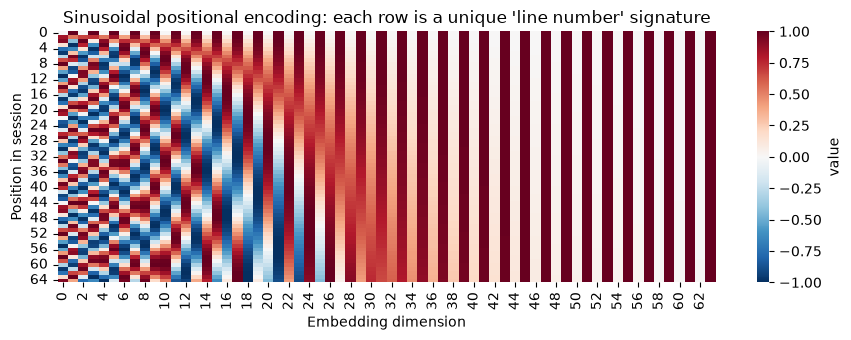

In [7]:
class PositionalEncoding(nn.Module):
    """Add fixed sinusoidal position signatures to event embeddings."""

    def __init__(self, d_model: int, max_len: int = MAX_LEN + 1, dropout: float = DROPOUT) -> None:
        super().__init__()
        position = torch.arange(max_len).unsqueeze(1)
        frequency = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        table = torch.zeros(max_len, d_model)
        table[:, 0::2] = torch.sin(position * frequency)
        table[:, 1::2] = torch.cos(position * frequency)
        self.register_buffer("table", table.unsqueeze(0))  # saved with model, not trained
        self.dropout = nn.Dropout(dropout)

    def forward(self, embeddings: torch.Tensor) -> torch.Tensor:
        """Add position signatures to a (batch, length, d_model) tensor."""
        return self.dropout(embeddings + self.table[:, : embeddings.size(1)])

positional_table = PositionalEncoding(D_MODEL).table[0].numpy()
plt.figure(figsize=(9, 3.5))
sns.heatmap(positional_table, cmap="RdBu_r", center=0, cbar_kws={"label": "value"})
plt.xlabel("Embedding dimension")
plt.ylabel("Position in session")
plt.title("Sinusoidal positional encoding: each row is a unique 'line number' signature")
plt.tight_layout()
plt.show()

## 8. Encoder Block และ `TransformerClassifier`

**Encoder Block** หนึ่งชั้นมี 2 ขั้น:
1. **Multi-Head Self-Attention** — ทุก event รวบรวมข้อมูลจาก event อื่นที่เกี่ยวข้อง (correlation)
2. **Feed-Forward** — แต่ละ event "คิดต่อ" กับข้อมูลที่รวบรวมมา

ทั้งสองขั้นมี **Residual connection** (`x + ...`) และ **LayerNorm**:
- Residual = เก็บข้อมูลเดิมไว้เสมอ แล้วเพิ่มสิ่งที่เรียนรู้ใหม่ทับลงไป (เหมือน enrich log ด้วย threat intel แต่ไม่ลบ field เดิม)
- LayerNorm = ปรับสเกลตัวเลขให้คงที่ ช่วยให้ train เสถียร

**TransformerClassifier** ภาพรวม:
```
[CLS, E5, E22, E5, ...]  ->  Embedding  ->  + Positional Encoding
                         ->  Encoder Block x 2   (เก็บ attention weights ไว้)
                         ->  เลือก vector ของ <CLS> (ตำแหน่ง 0)
                         ->  Linear  ->  1 logit  ->  sigmoid = P(Anomaly)
```
> เราเขียน block เองด้วย `nn.MultiheadAttention` แทน `nn.TransformerEncoderLayer` เพราะตัวสำเร็จรูปไม่คืน attention weights ซึ่งเราต้องใช้ทำ heatmap ใน Part 3
> ตอน train เราไม่ขอ attention weights (`return_attention=False`) เพื่อประหยัดเวลาคำนวณ — ขอเฉพาะตอนวิเคราะห์

In [8]:
class EncoderBlock(nn.Module):
    """One Transformer encoder layer that also returns its attention weights."""

    def __init__(self, d_model: int, num_heads: int, ff_dim: int, dropout: float) -> None:
        super().__init__()
        self.attention = nn.MultiheadAttention(d_model, num_heads, dropout=dropout, batch_first=True)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, ff_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(ff_dim, d_model))
        self.norm_attention = nn.LayerNorm(d_model)
        self.norm_feed_forward = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor, padding_mask: torch.Tensor, need_weights: bool = False
                ) -> Tuple[torch.Tensor, torch.Tensor | None]:
        """Return updated event vectors and, if requested, per-head attention (batch, heads, L, L)."""
        attended, weights = self.attention(x, x, x, key_padding_mask=padding_mask,
                                           need_weights=need_weights, average_attn_weights=False)
        x = self.norm_attention(x + self.dropout(attended))
        x = self.norm_feed_forward(x + self.dropout(self.feed_forward(x)))
        return x, weights


class TransformerClassifier(nn.Module):
    """Session-level anomaly classifier that reads the [CLS] token output."""

    def __init__(self, vocab_size: int, d_model: int = D_MODEL, num_heads: int = NUM_HEADS,
                 num_layers: int = NUM_LAYERS, ff_dim: int = FF_DIM, dropout: float = DROPOUT) -> None:
        super().__init__()
        self.d_model = d_model
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.positional = PositionalEncoding(d_model, dropout=dropout)
        self.blocks = nn.ModuleList(
            EncoderBlock(d_model, num_heads, ff_dim, dropout) for _ in range(num_layers))
        self.classifier = nn.Linear(d_model, 1)

    def forward(self, inputs: torch.Tensor, padding_mask: torch.Tensor, return_attention: bool = False):
        """Return anomaly logits, plus a list of per-layer attention maps if requested."""
        x = self.positional(self.embedding(inputs) * math.sqrt(self.d_model))
        attention_maps: List[torch.Tensor] = []
        for block in self.blocks:
            x, weights = block(x, padding_mask, need_weights=return_attention)
            if return_attention:
                attention_maps.append(weights)
        logits = self.classifier(x[:, 0]).squeeze(-1)  # position 0 = <CLS>
        return (logits, attention_maps) if return_attention else logits


set_seed()
model = TransformerClassifier(vocab_size=len(event_to_id)).to(DEVICE)
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"[8] Trainable parameters: {parameter_count:,}")

# Shape check with one batch before training
with torch.no_grad():
    sample_logits, sample_attention = model(inputs.to(DEVICE), padding_mask.to(DEVICE), return_attention=True)
print(f"    logits shape:    {tuple(sample_logits.shape)}   (one score per session)")
print(f"    attention shape: {tuple(sample_attention[0].shape)}   (batch, heads, L, L) per layer")

[8] Trainable parameters: 70,081


    logits shape:    (256,)   (one score per session)
    attention shape: (256, 4, 36, 36)   (batch, heads, L, L) per layer


## 9. Loss function ที่ชดเชย class imbalance

Anomaly มีแค่ ~2.9% ถ้าใช้ loss ปกติ โมเดลจะ "ขี้เกียจ" ทาย Normal ตลอด (Accuracy Paradox)
จึงใช้ `BCEWithLogitsLoss(pos_weight=...)` ให้การพลาด Anomaly หนึ่งครั้ง **มีโทษหนักกว่า ~33 เท่า**
เหมือน SOC ที่ถือว่าปล่อย intrusion หลุดหนึ่งครั้งร้ายแรงกว่า false alarm หลายสิบครั้ง (ใช้ค่าเดียวกับ LSTM ใน Week 4)

Optimizer: **AdamW** + **gradient clipping** (จำกัดขนาดการปรับ weight ต่อก้าว กัน training ระเบิด)

In [9]:
negatives = int((train["Label"] == 0).sum())
positives = int((train["Label"] == 1).sum())
pos_weight = torch.tensor(negatives / positives, dtype=torch.float32, device=DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
print(f"[9] pos_weight (Normal/Anomaly) = {pos_weight.item():.2f}")

[9] pos_weight (Normal/Anomaly) = 33.15


## 10. Training loop

ทุก epoch: train บน train set แล้ววัด loss บน validation set
เก็บ weights ของ epoch ที่ **validation loss ต่ำสุด** ไว้ (กัน overfit — เหมือนเลือก rule set เวอร์ชันที่ทำงานดีที่สุดบนข้อมูลที่ไม่เคยเห็น)

    batch 393/1,573 | loss=0.0042
    batch 786/1,573 | loss=0.3460
    batch 1,179/1,573 | loss=0.0018
    batch 1,572/1,573 | loss=0.0015
Epoch 1/5 | train_loss=0.0555 | val_loss=0.0137 | time=770.1s
    batch 393/1,573 | loss=0.0007
    batch 786/1,573 | loss=0.0008
    batch 1,179/1,573 | loss=0.0256
    batch 1,572/1,573 | loss=0.0006
Epoch 2/5 | train_loss=0.0125 | val_loss=0.0116 | time=794.4s
    batch 393/1,573 | loss=0.0322
    batch 786/1,573 | loss=0.0252
    batch 1,179/1,573 | loss=0.0002
    batch 1,572/1,573 | loss=0.0005
Epoch 3/5 | train_loss=0.0112 | val_loss=0.0087 | time=802.7s
    batch 393/1,573 | loss=0.0063
    batch 786/1,573 | loss=0.0232
    batch 1,179/1,573 | loss=0.0026
    batch 1,572/1,573 | loss=0.0422
Epoch 4/5 | train_loss=0.0141 | val_loss=0.0065 | time=759.9s
    batch 393/1,573 | loss=0.0002
    batch 786/1,573 | loss=0.0005
    batch 1,179/1,573 | loss=0.0007
    batch 1,572/1,573 | loss=0.0010
Epoch 5/5 | train_loss=0.0099 | val_loss=0.0071 | ti

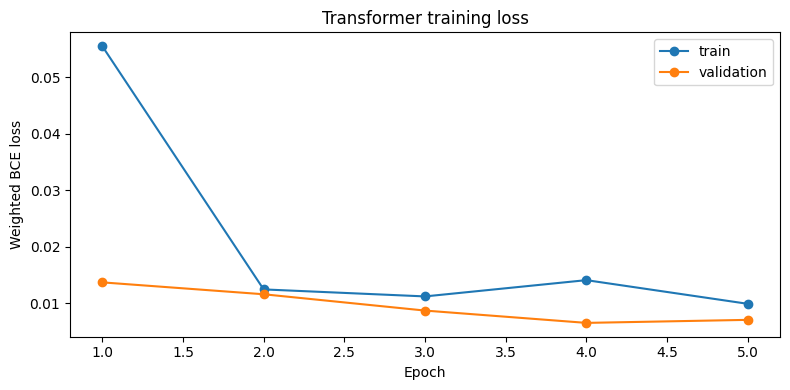

In [14]:
def run_epoch(model: nn.Module, loader: DataLoader, criterion: nn.Module,
              optimizer: torch.optim.Optimizer | None = None) -> float:
    """Run one training (if optimizer given) or evaluation pass and return mean loss."""
    training = optimizer is not None
    model.train(training)
    total_loss, total_items = 0.0, 0
    with torch.set_grad_enabled(training):
        for batch_number, (batch_inputs, batch_mask, batch_labels) in enumerate(loader, start=1):
            batch_inputs, batch_mask = batch_inputs.to(DEVICE), batch_mask.to(DEVICE)
            batch_labels = batch_labels.to(DEVICE)
            loss = criterion(model(batch_inputs, batch_mask), batch_labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                if batch_number % max(1, len(loader) // 4) == 0:
                    print(f"    batch {batch_number:,}/{len(loader):,} | loss={loss.item():.4f}", flush=True)
            total_loss += loss.item() * len(batch_labels)
            total_items += len(batch_labels)
    return total_loss / max(1, total_items)

train_losses, validation_losses = [], []
best_validation_loss, best_epoch, best_state = float("inf"), 0, None
for epoch in range(1, NUM_EPOCHS + 1):
    started = time.perf_counter()
    train_loss = run_epoch(model, train_loader, criterion, optimizer)
    validation_loss = run_epoch(model, validation_loader, criterion)
    train_losses.append(train_loss)
    validation_losses.append(validation_loss)
    if validation_loss < best_validation_loss:
        best_validation_loss, best_epoch = validation_loss, epoch
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
        torch.save({"model_state_dict": best_state, "epoch": epoch},
                   CHECKPOINT_DIR / "transformer_hdfs_training.pt")  # resume point if training crashes
    print(f"Epoch {epoch}/{NUM_EPOCHS} | train_loss={train_loss:.4f} | val_loss={validation_loss:.4f} "
          f"| time={time.perf_counter() - started:.1f}s", flush=True)

model.load_state_dict(best_state)
print(f"[10] Restored best epoch {best_epoch} (val_loss={best_validation_loss:.4f})")

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.figure(figsize=(8, 4))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses, marker="o", label="train")
plt.plot(range(1, NUM_EPOCHS + 1), validation_losses, marker="o", label="validation")
plt.xlabel("Epoch")
plt.ylabel("Weighted BCE loss")
plt.title("Transformer training loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "09_transformer_training_loss.png", dpi=150)
plt.show()

## 11. เลือก threshold จาก validation F1

โมเดลให้ความน่าจะเป็น 0-1 เราต้องเลือกจุดตัดว่า "สูงเท่าไรถึงยิง alert"
เลือกบน **validation** เท่านั้น (ห้ามแตะ test) เหมือนการ tune rule threshold บน lab ก่อนใช้งานจริง

**ทำไมไม่เลือกจุดที่ F1 สูงสุดตรงๆ?** จุดสูงสุดอาจเป็น**ยอดแหลม**ที่กว้างแค่จุดเดียว (เช่นที่ threshold 0.99)
- ข้อมูลจริงขยับนิดเดียว ผลจะร่วงทันที
- ที่ 0.99 anomaly กลุ่มล่างสุดได้คะแนนแค่ ~0.991 → อยู่เหนือเส้นแจ้งเตือนเพียงนิดเดียว เสี่ยงหลุดรอด

**กฎที่ใช้ (ทีมเลือกตามหลัก SOC):** หา**ช่วงต่อเนื่องที่กว้างที่สุด**ซึ่ง F1 ห่างจากค่าสูงสุดไม่เกิน **0.01** แล้วเลือก**จุดกึ่งกลาง**
- ยอมเสีย F1 ไม่เกิน 1 จุด แลกกับ threshold ที่ทนทาน และ Recall สูงสุด (ไม่ปล่อยการโจมตีหลุด)

> 🛡️ SOC: ตั้ง alert threshold ไว้กลางช่องว่างระหว่าง traffic ปกติกับ traffic โจมตี ไม่ใช่ชิดขอบด้านใดด้านหนึ่ง
> การพลาด intrusion 1 ครั้งร้ายแรงกว่า false alarm เพิ่มอีกหลายสิบครั้ง

[11] Best validation F1 = 0.9947 (first reached at threshold 0.990)
     Widest plateau within 0.01 of best F1: 0.465 - 0.990
     Chosen threshold (plateau center) = 0.728 -> validation F1 = 0.9896
     Normal sessions within 0.05 below threshold: 0 (vs 36 for the first-best threshold)


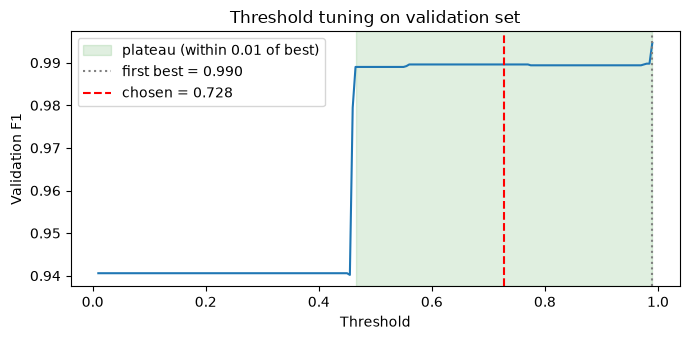

In [11]:
@torch.no_grad()
def predict_probabilities(model: nn.Module, loader: DataLoader) -> np.ndarray:
    """Return anomaly probabilities for every session in a loader."""
    model.eval()
    probabilities = []
    for batch_inputs, batch_mask, _ in loader:
        logits = model(batch_inputs.to(DEVICE), batch_mask.to(DEVICE))
        probabilities.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(probabilities).astype(np.float64)

def plateau_center_threshold(thresholds: np.ndarray, scores: List[float],
                             tolerance: float = 0.01) -> Tuple[float, float, float]:
    """Return (center, low, high) of the widest contiguous region whose score is within tolerance of the best."""
    scores = np.asarray(scores)
    near_best = scores >= scores.max() - tolerance
    best_run, run_start = (0, 0), None
    for index, flag in enumerate(np.append(near_best, False)):   # sentinel closes the last run
        if flag and run_start is None:
            run_start = index
        elif not flag and run_start is not None:
            if index - run_start > best_run[1] - best_run[0] + 1:
                best_run = (run_start, index - 1)
            run_start = None
    low, high = thresholds[best_run[0]], thresholds[best_run[1]]
    return float((low + high) / 2), float(low), float(high)

validation_probabilities = predict_probabilities(model, validation_loader)
thresholds = np.linspace(0.01, 0.99, 197)
validation_f1 = [f1_score(validation["Label"], validation_probabilities >= value, zero_division=0)
                 for value in thresholds]
threshold, plateau_low, plateau_high = plateau_center_threshold(thresholds, validation_f1)
first_best = float(thresholds[int(np.argmax(validation_f1))])
threshold_f1 = f1_score(validation["Label"], validation_probabilities >= threshold, zero_division=0)
print(f"[11] Best validation F1 = {max(validation_f1):.4f} (first reached at threshold {first_best:.3f})")
print(f"     Widest plateau within 0.01 of best F1: {plateau_low:.3f} - {plateau_high:.3f}")
print(f"     Chosen threshold (plateau center) = {threshold:.3f} -> validation F1 = {threshold_f1:.4f}")
normal_scores = validation_probabilities[validation["Label"].to_numpy() == 0]
print(f"     Normal sessions within 0.05 below threshold: {int(((normal_scores < threshold) & (normal_scores >= threshold - 0.05)).sum()):,} "
      f"(vs {int(((normal_scores < first_best) & (normal_scores >= first_best - 0.05)).sum()):,} for the first-best threshold)")

plt.figure(figsize=(7, 3.5))
plt.plot(thresholds, validation_f1)
plt.axvspan(plateau_low, plateau_high, color="green", alpha=0.12, label="plateau (within 0.01 of best)")
plt.axvline(first_best, color="gray", linestyle=":", label=f"first best = {first_best:.3f}")
plt.axvline(threshold, color="red", linestyle="--", label=f"chosen = {threshold:.3f}")
plt.xlabel("Threshold")
plt.ylabel("Validation F1")
plt.title("Threshold tuning on validation set")
plt.legend()
plt.tight_layout()
plt.show()

## 12. ประเมินบน test set และบันทึกผล

test set คือ "ข้อมูลจริงที่ไม่เคยเห็น" — วัดผลครั้งเดียวด้วย threshold ที่เลือกไว้แล้ว

{
  "precision": 0.9813,
  "recall": 0.9996,
  "f1_score": 0.9904,
  "pr_auc": 0.9997
}

SOC view: caught 2,525/2,526 anomalies | missed 1 | false alarms 48


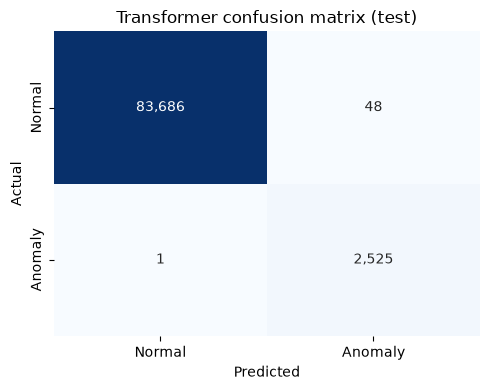

In [12]:
test_probabilities = predict_probabilities(model, test_loader)
test_labels = test["Label"].to_numpy()
test_predictions = (test_probabilities >= threshold).astype(int)
test_matrix = confusion_matrix(test_labels, test_predictions)
metrics = {
    "precision": round(float(precision_score(test_labels, test_predictions, zero_division=0)), 4),
    "recall": round(float(recall_score(test_labels, test_predictions, zero_division=0)), 4),
    "f1_score": round(float(f1_score(test_labels, test_predictions, zero_division=0)), 4),
    "pr_auc": round(float(average_precision_score(test_labels, test_probabilities)), 4),
}
print(json.dumps(metrics, indent=2))
tn, fp, fn, tp = test_matrix.ravel()
print(f"\nSOC view: caught {tp:,}/{tp + fn:,} anomalies | missed {fn:,} | false alarms {fp:,}")

plt.figure(figsize=(5, 4))
sns.heatmap(test_matrix, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Transformer confusion matrix (test)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "10_transformer_confusion_matrix.png", dpi=150)
plt.show()

In [13]:
hyperparameters = {
    "d_model": D_MODEL, "num_heads": NUM_HEADS, "num_layers": NUM_LAYERS, "ff_dim": FF_DIM,
    "dropout": DROPOUT, "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE, "epochs": NUM_EPOCHS, "best_epoch": best_epoch, "max_len": MAX_LEN,
}

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
torch.save({
    "model_state_dict": model.state_dict(),
    "event_to_id": event_to_id,
    "id_to_event": id_to_event,
    "hyperparameters": hyperparameters,
    "threshold": threshold,
    "seed": SEED,
}, CHECKPOINT_DIR / "transformer_hdfs.pt")

payload = {
    "model": "TransformerEncoder",
    "dataset": "HDFS",
    **metrics,
    "threshold": round(threshold, 4),
    "confusion_matrix": test_matrix.tolist(),
    "class_weight_anomaly": round(pos_weight.item(), 4),
    "trainable_parameters": parameter_count,
    "hyperparameters": hyperparameters,
    "device": str(DEVICE),
    "seed": SEED,
    "timestamp": datetime.now().isoformat(timespec="seconds"),
}
RESULT_DIR.mkdir(parents=True, exist_ok=True)
with open(RESULT_DIR / "transformer_hdfs.json", "w", encoding="utf-8") as handle:
    json.dump(payload, handle, indent=2)
print("[12] Saved checkpoints/transformer_hdfs.pt and results/metrics/transformer_hdfs.json")

[12] Saved checkpoints/transformer_hdfs.pt and results/metrics/transformer_hdfs.json


## 13. เทียบกับโมเดลก่อนหน้า

อ่านไฟล์ JSON ของทุกโมเดลใน `results/metrics/` มาเทียบกัน (Week 6 จะวิเคราะห์ละเอียดกว่านี้)

In [14]:
rows = []
for metrics_path in sorted(RESULT_DIR.glob("*_hdfs.json")):
    record = json.loads(metrics_path.read_text(encoding="utf-8"))
    rows.append({"model": record["model"], "f1": record.get("f1_score"),
                 "precision": record.get("precision"), "recall": record.get("recall"),
                 "pr_auc": record.get("pr_auc")})
comparison = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
comparison

,model,f1,precision,recall,pr_auc
0,TransformerEncoder,0.9904,0.9813,0.9996,0.9997
1,SupervisedSessionLSTM,0.9871,0.9764,0.9980,0.9996
2,logistic_regression,0.9802,0.9612,1.0000,0.9753
3,DeepLog_NextEvent_EOS_ProbThreshold,0.9278,0.9594,0.8983,0.9842
4,DeepLog_NextEvent,0.6793,0.9034,0.5443,NaN
5,isolation_forest,0.6369,0.6474,0.6267,0.7336


# Part 3 — Attention Explainability สำหรับ SOC Analyst

## 14. แนวคิด: ถาม "หัวหน้ากะ" ว่าดูบรรทัดไหน

`<CLS>` คือ "หัวหน้ากะ" ที่อ่านทั้ง session แล้วออก verdict — **attention ของ `<CLS>`** บอกว่าเขาให้น้ำหนักกับ event ไหนตอนตัดสินใจ
ทำให้ alert ไม่ใช่แค่ "Anomaly 0.98" แต่เป็น "Anomaly 0.98 — **เพราะเห็น writeBlock exception ตรงบรรทัดที่ 7**"

| สิ่งที่ดู | อ่านอย่างไร |
|---|---|
| Attention weight | สัดส่วนความสนใจ (รวมทั้ง session = 1) |
| **Attention lift** = weight × จำนวน event | 1.0 = มองเท่าค่าเฉลี่ย, 3.0 = มองมากกว่าค่าเฉลี่ย 3 เท่า (เทียบ session ยาวไม่เท่ากันได้) |

ใช้ attention ของ **layer สุดท้าย** (ชั้นที่อยู่ติดกับการตัดสินใจ) เฉลี่ยทุก head

> ⚠️ **ข้อจำกัด:** attention บอกว่าโมเดล **"มองตรงไหน"** ไม่ใช่หลักฐานว่า **"ตัดสินเพราะสิ่งนั้น"** 100%
> ใช้เป็น *เบาะแสนำทาง* ให้ analyst ตรวจต่อ เหมือนคำบอกเล่าของเพื่อนร่วมทีม — มีประโยชน์ แต่ต้องยืนยันด้วย log จริง

### 14.1 โหลดข้อความ template จาก Drain3
รหัส `E1...E45` มาจาก Drain3 ใน Week 2 (**ไม่ตรงกับ** `HDFS.log_templates.csv` ของ Loghub ที่มี 29 แบบ) จึงต้องอ่านจาก state ของ Drain3 เอง

In [15]:
import shutil
import tempfile
from drain3 import TemplateMiner
from drain3.file_persistence import FilePersistence
from drain3.template_miner_config import TemplateMinerConfig

def load_event_templates(state_path: Path) -> Dict[str, str]:
    """Read {"E<id>": template} from a saved Drain3 state (works on a temp copy; the original is never modified)."""
    with tempfile.TemporaryDirectory() as tmp:
        copy_path = Path(tmp) / "drain3_state.bin"
        shutil.copy(state_path, copy_path)
        config = TemplateMinerConfig()
        config.profiling_enabled = False
        miner = TemplateMiner(FilePersistence(str(copy_path)), config)
        return {f"E{c.cluster_id}": c.get_template() for c in miner.drain.clusters}

def short_template(event: str, width: int = 48) -> str:
    """Return 'E5: <template>' shortened for plot labels."""
    text = event_templates.get(event, "?").replace("<BLK>", "blk").replace("<IP>", "ip").replace("<NUM>", "n")
    return f"{event}: {text[:width]}{'…' if len(text) > width else ''}"

event_templates = load_event_templates(CHECKPOINT_DIR / "drain3_hdfs.bin")
print(f"[14] Loaded {len(event_templates)} templates")
for event in ("E17", "E5", "E16", "E33"):
    print(f"   {short_template(event, 90)}")

[14] Loaded 45 templates
   E17: Deleting block blk file <*>
   E5: BLOCK* NameSystem.addStoredBlock: blockMap updated: ip is added to blk size n
   E16: writeBlock blk received exception java.io.IOException: Could not read from stream
   E33: Unexpected error trying to delete block blk. BlockInfo not found in volumeMap.


## 15. `explain_session`: อธิบาย session เดียว

รับ `Sequence` 1 session → คืน (1) ความน่าจะเป็น Anomaly, (2) event แต่ละตัว, (3) attention ของ `<CLS>` ที่มีต่อแต่ละ event
แล้วสร้าง **"alert explanation"** แบบที่ analyst อ่านได้ทันที: 3 event ที่โมเดลให้น้ำหนักมากที่สุด

In [16]:
@torch.no_grad()
def explain_session(sequence: str) -> Tuple[float, List[str], np.ndarray]:
    """Return (anomaly probability, events, last-layer [CLS] attention over events renormalized to sum 1)."""
    model.eval()
    events = str(sequence).split()[:MAX_LEN]
    inputs = torch.tensor([encode_session(sequence, event_to_id)], device=DEVICE)
    padding = torch.zeros_like(inputs, dtype=torch.bool)
    logits, attention_maps = model(inputs, padding, return_attention=True)
    cls_attention = attention_maps[-1][0, :, 0, 1:].mean(dim=0).cpu().numpy()   # heads averaged, skip [CLS] itself
    return float(torch.sigmoid(logits)[0]), events, cls_attention / cls_attention.sum()

def alert_explanation(sequence: str, top_n: int = 3) -> str:
    """Format a SOC-style alert: verdict, score, and the events the model attended to most."""
    probability, events, weights = explain_session(sequence)
    verdict = "🚨 ANOMALY" if probability >= threshold else "✅ normal"
    lines = [f"{verdict}  score={probability:.3f}  threshold={threshold:.3f}  events={len(events)}"]
    for rank, position in enumerate(np.argsort(weights)[::-1][:top_n], start=1):
        lift = weights[position] * len(events)
        lines.append(f"  #{rank} line {position + 1:>2} | lift {lift:4.1f}x | {short_template(events[position], 70)}")
    return "\n".join(lines)

test_frame = test.reset_index(drop=True).assign(score=test_probabilities, predicted=test_predictions)
example_anomaly = test_frame[(test_frame.Label == 1) & (test_frame.predicted == 1)].iloc[0]
print("[15] Example alert for a detected anomaly:\n")
print(alert_explanation(example_anomaly.Sequence))

[15] Example alert for a detected anomaly:

🚨 ANOMALY  score=1.000  threshold=0.728  events=20
  #1 line 18 | lift  7.4x | E33: Unexpected error trying to delete block blk. BlockInfo not found in vo…
  #2 line 11 | lift  2.2x | E5: BLOCK* NameSystem.addStoredBlock: blockMap updated: ip is added to blk…
  #3 line 12 | lift  2.2x | E5: BLOCK* NameSystem.addStoredBlock: blockMap updated: ip is added to blk…


## 16. Heatmap 4 กรณี — Post-Incident Review

เหมือนการทบทวนเคสหลังเหตุการณ์ใน SOC เราดูทั้งเคสที่ถูกและผิด:

| กรณี | ความหมาย | สิ่งที่อยากรู้ |
|---|---|---|
| **True Positive** | จับ anomaly ได้ | โมเดลใช้ event ไหนเป็นหลักฐาน? |
| **False Negative** | anomaly หลุดรอด | ทำไมมองไม่เห็น? |
| **False Positive** | Normal แต่แจ้งเตือน | อะไรทำให้เข้าใจผิด? |
| **True Negative** | Normal ทายถูก | โมเดลมองอะไรเมื่อทุกอย่างปกติ? |

แต่ละแถบคือ 1 session (ซ้ายไปขวา = ลำดับ log) สีเข้ม = attention สูง

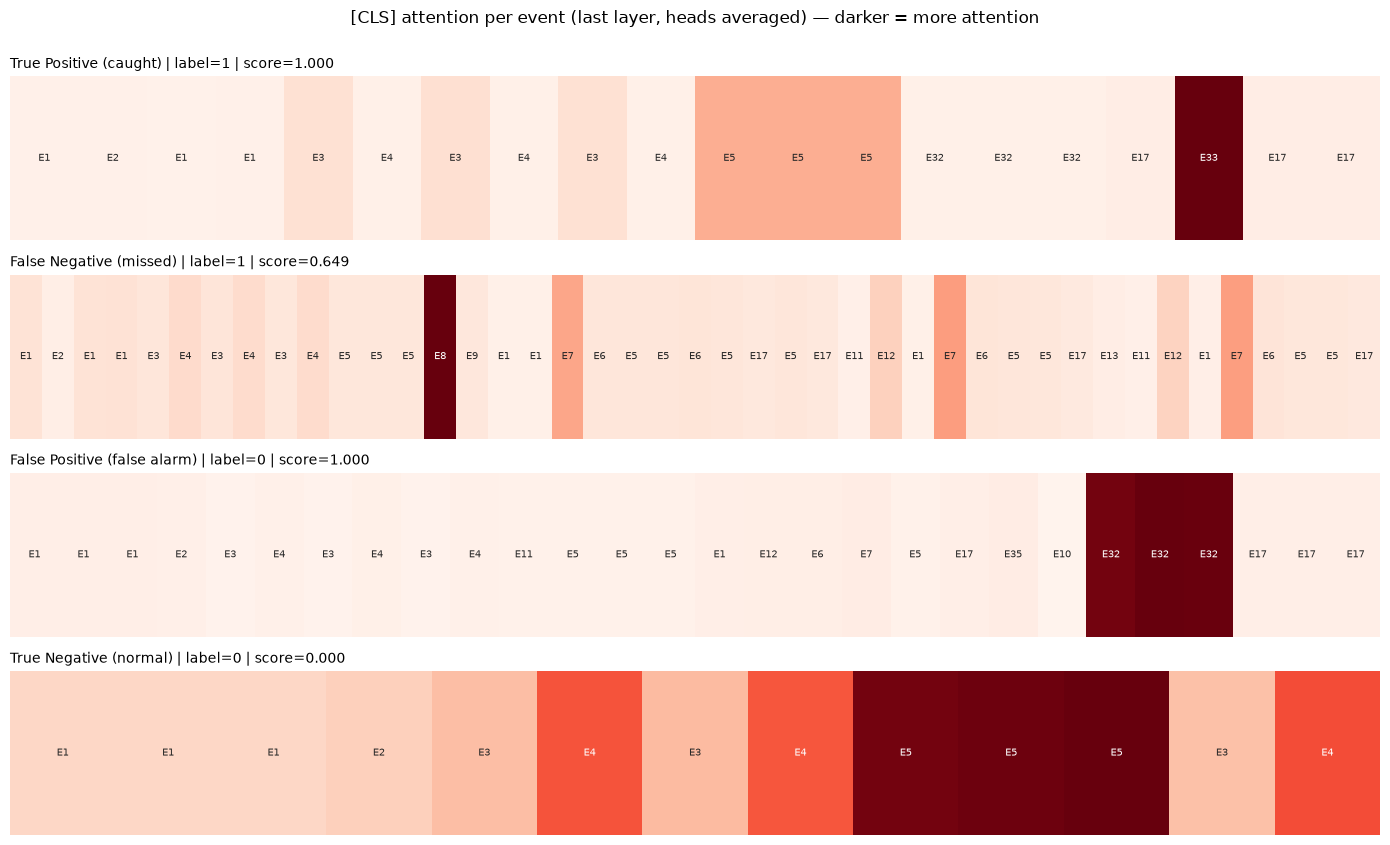


=== True Positive (caught) ===
🚨 ANOMALY  score=1.000  threshold=0.728  events=20
  #1 line 18 | lift  7.4x | E33: Unexpected error trying to delete block blk. BlockInfo not found in vo…
  #2 line 11 | lift  2.2x | E5: BLOCK* NameSystem.addStoredBlock: blockMap updated: ip is added to blk…
  #3 line 12 | lift  2.2x | E5: BLOCK* NameSystem.addStoredBlock: blockMap updated: ip is added to blk…

=== False Negative (missed) ===
✅ normal  score=0.649  threshold=0.728  events=43
  #1 line 14 | lift  7.9x | E8: ip Starting thread to transfer block blk to ip, ip
  #2 line 30 | lift  2.7x | E7: ip:Transmitted block blk to /ip
  #3 line 39 | lift  2.6x | E7: ip:Transmitted block blk to /ip

=== False Positive (false alarm) ===


🚨 ANOMALY  score=1.000  threshold=0.728  events=28
  #1 line 24 | lift  7.3x | E32: BLOCK* NameSystem.delete: blk is added to invalidSet of ip
  #2 line 25 | lift  7.3x | E32: BLOCK* NameSystem.delete: blk is added to invalidSet of ip
  #3 line 23 | lift  7.1x | E32: BLOCK* NameSystem.delete: blk is added to invalidSet of ip

=== True Negative (normal) ===
✅ normal  score=0.000  threshold=0.728  events=13
  #1 line 11 | lift  2.2x | E5: BLOCK* NameSystem.addStoredBlock: blockMap updated: ip is added to blk…
  #2 line 10 | lift  2.1x | E5: BLOCK* NameSystem.addStoredBlock: blockMap updated: ip is added to blk…
  #3 line  9 | lift  2.1x | E5: BLOCK* NameSystem.addStoredBlock: blockMap updated: ip is added to blk…


In [17]:
def pick_case(label: int, predicted: int) -> pd.Series | None:
    """Pick a representative example of a confusion-matrix cell (None if the cell is empty).

    True Positive: a confident detection (score >= 0.99) whose length is closest to the median anomaly length,
    so the heatmap is readable. Other cells: the most extreme score (closest call for errors, clearest normal).
    """
    subset = test_frame[(test_frame.Label == label) & (test_frame.predicted == predicted)]
    if subset.empty:
        return None
    if label == 1 and predicted == 1:
        confident = subset[subset.score >= 0.99]
        lengths = confident.Sequence.str.split().str.len()
        median_length = test_frame[test_frame.Label == 1].Sequence.str.split().str.len().median()
        return confident.loc[(lengths - median_length).abs().idxmin()]
    return subset.loc[subset.score.idxmax() if predicted == 1 else subset.score.idxmin()]

cases = {"True Positive (caught)": pick_case(1, 1), "False Negative (missed)": pick_case(1, 0),
         "False Positive (false alarm)": pick_case(0, 1), "True Negative (normal)": pick_case(0, 0)}
cases = {name: row for name, row in cases.items() if row is not None}

fig, axes = plt.subplots(len(cases), 1, figsize=(14, 2.1 * len(cases)))
for ax, (name, row) in zip(np.atleast_1d(axes), cases.items()):
    probability, events, weights = explain_session(row.Sequence)
    sns.heatmap(weights[None, :], ax=ax, cmap="Reds", cbar=False, vmin=0,
                annot=np.array([events]), fmt="", annot_kws={"fontsize": 7},
                xticklabels=False, yticklabels=False)
    ax.set_title(f"{name} | label={row.Label} | score={probability:.3f}", fontsize=10, loc="left")
plt.suptitle("[CLS] attention per event (last layer, heads averaged) — darker = more attention", y=1.0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "11_transformer_attention_examples.png", dpi=150, bbox_inches="tight")
plt.show()

for name, row in cases.items():
    print(f"\n=== {name} ===")
    print(alert_explanation(row.Sequence))

## 17. ภาพรวม: โมเดลใช้ event ประเภทไหนเป็น "signature"?

ดูทีละ session ยังไม่พอ — เรารวม attention ของ **ทุก session ใน test set** แล้วถามว่า
*"event ประเภทนี้ เมื่อปรากฏ ถูกมองมากกว่าค่าเฉลี่ยกี่เท่า?"* (attention lift เฉลี่ย) แยกระหว่าง session Normal และ Anomaly

> 🛡️ เหมือนการ review SIEM rule: ดูว่า rule ของเรา trigger จาก field ไหนบ่อยที่สุด — ถ้าเป็น field ที่สมเหตุสมผล (exception, error) แปลว่า rule น่าเชื่อถือ

[17] Computed attention lift over 86,260 test sessions in 15.0s


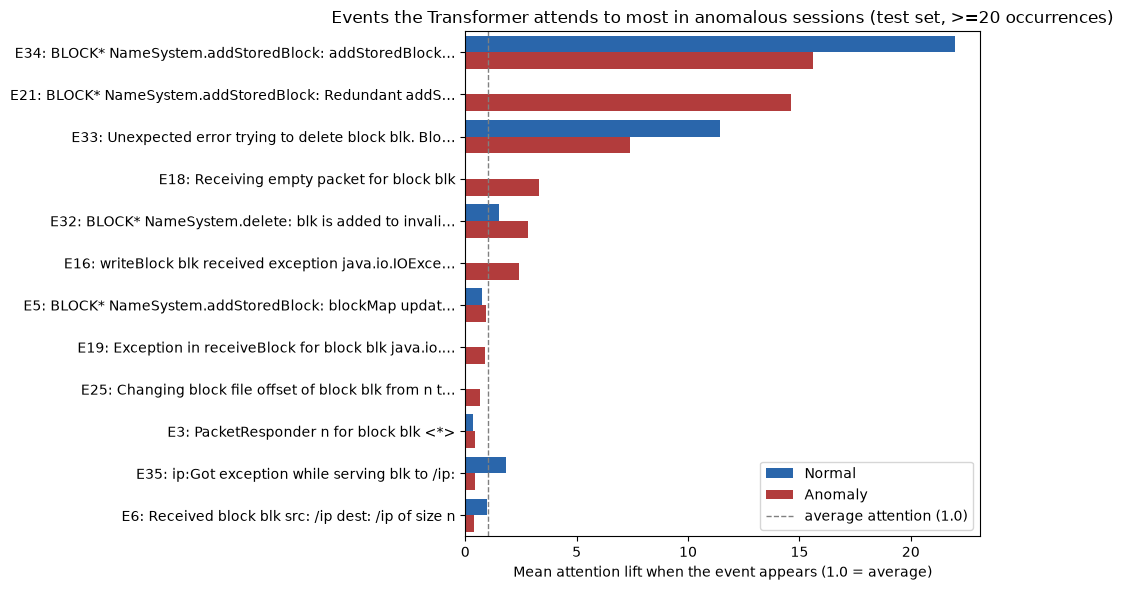

,event,mean_lift,occurrences,template
0,E34,15.60,191,BLOCK* NameSystem.addStoredBlock: addStoredBlo...
1,E21,14.61,158,BLOCK* NameSystem.addStoredBlock: Redundant ad...
2,E33,7.39,783,Unexpected error trying to delete block <BLK>....
3,E18,3.32,198,Receiving empty packet for block <BLK>
4,E32,2.82,4851,BLOCK* NameSystem.delete: <BLK> is added to in...
5,E16,2.39,480,writeBlock <BLK> received exception java.io.IO...
6,E5,0.92,6209,BLOCK* NameSystem.addStoredBlock: blockMap upd...
7,E19,0.87,22,Exception in receiveBlock for block <BLK> java...
8,E25,0.66,22,Changing block file offset of block <BLK> from...
9,E3,0.46,4934,PacketResponder <NUM> for block <BLK> <*>


In [18]:
@torch.no_grad()
def attention_lift_by_event(loader: DataLoader, labels: np.ndarray) -> pd.DataFrame:
    """Average attention lift (weight x session length) per event type, split by true label."""
    model.eval()
    totals = {0: {}, 1: {}}
    offset = 0
    for batch_inputs, batch_mask, _ in loader:
        _, attention_maps = model(batch_inputs.to(DEVICE), batch_mask.to(DEVICE), return_attention=True)
        cls = attention_maps[-1][:, :, 0, 1:].mean(dim=1).cpu().numpy()        # (batch, events)
        events = batch_inputs[:, 1:].numpy()
        valid = events != PAD_ID
        cls = np.where(valid, cls, 0.0)
        lifts = cls / cls.sum(axis=1, keepdims=True) * valid.sum(axis=1, keepdims=True)
        for row in range(len(events)):
            bucket = totals[int(labels[offset + row])]
            for event_id, lift in zip(events[row][valid[row]], lifts[row][valid[row]]):
                total, count = bucket.get(event_id, (0.0, 0))
                bucket[event_id] = (total + float(lift), count + 1)
        offset += len(events)
    rows = [{"event": id_to_event[e], "label": "Anomaly" if lab else "Normal", "mean_lift": t / c, "occurrences": c}
            for lab, bucket in totals.items() for e, (t, c) in bucket.items()]
    return pd.DataFrame(rows)

t0 = time.perf_counter()
lift_table = attention_lift_by_event(test_loader, test["Label"].to_numpy())
print(f"[17] Computed attention lift over {len(test):,} test sessions in {time.perf_counter() - t0:.1f}s")

top_anomaly = (lift_table[(lift_table.label == "Anomaly") & (lift_table.occurrences >= 20)]
               .nlargest(12, "mean_lift"))
plot_table = lift_table[lift_table.event.isin(top_anomaly.event)].copy()
plot_table["template"] = plot_table.event.map(short_template)
order = top_anomaly.event.map(short_template).tolist()

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_table, y="template", x="mean_lift", hue="label", order=order,
            palette={"Anomaly": "#C62828", "Normal": "#1565C0"})
plt.axvline(1.0, color="gray", linestyle="--", linewidth=1, label="average attention (1.0)")
plt.xlabel("Mean attention lift when the event appears (1.0 = average)")
plt.ylabel("")
plt.title("Events the Transformer attends to most in anomalous sessions (test set, >=20 occurrences)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "12_transformer_attention_by_event.png", dpi=150, bbox_inches="tight")
plt.show()

summary = top_anomaly[["event", "mean_lift", "occurrences"]].assign(template=top_anomaly.event.map(lambda e: event_templates.get(e, "?")[:70]))
summary.round(2).reset_index(drop=True)

## 18. Multi-Head: analyst 4 คนดูคนละมุม

แต่ละ head เรียน "รูปแบบการมอง" ต่างกัน — เราดู attention matrix เต็ม (ทุก event มองทุก event) ของ layer สุดท้ายสำหรับเคส True Positive
- แกน Y = event ที่ "ถาม" (query), แกน X = event ที่ "ถูกมอง" (key)
- แถวบนสุด (`CLS`) คือสิ่งที่ส่งไปให้การตัดสินใจ

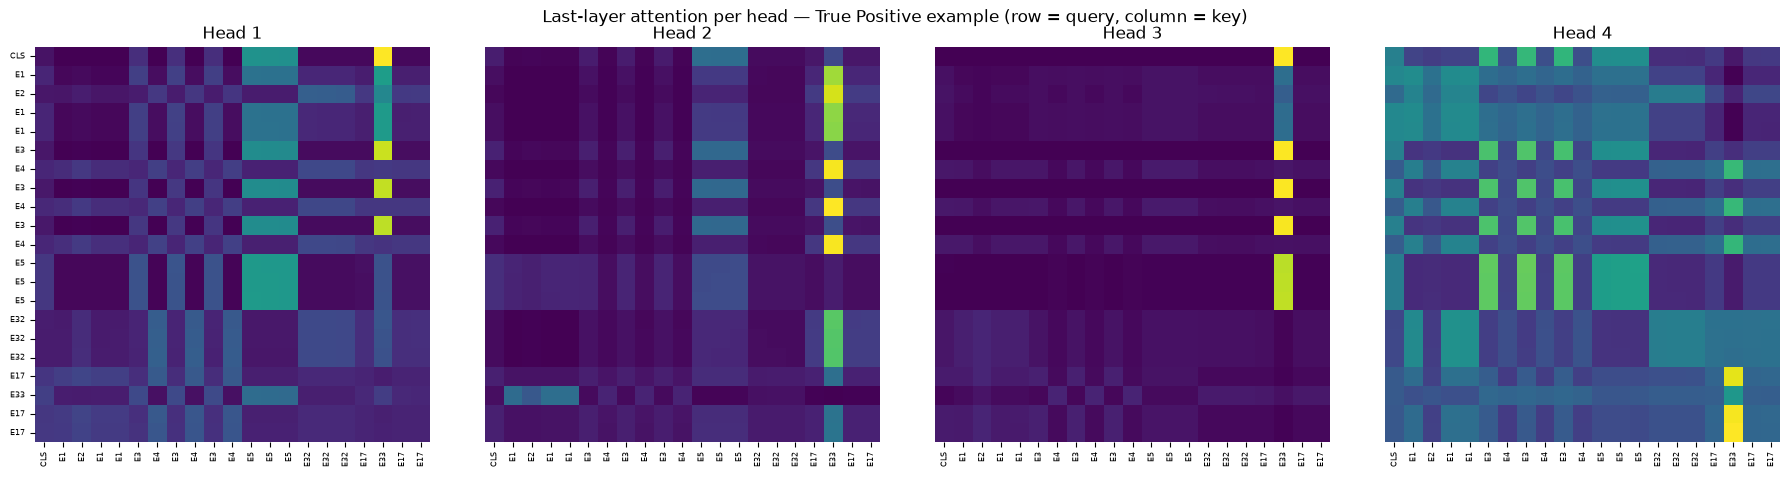

In [19]:
@torch.no_grad()
def head_attention(sequence: str) -> Tuple[List[str], np.ndarray]:
    """Return token labels and last-layer attention for every head: (heads, L+1, L+1)."""
    model.eval()
    inputs = torch.tensor([encode_session(sequence, event_to_id)], device=DEVICE)
    _, attention_maps = model(inputs, torch.zeros_like(inputs, dtype=torch.bool), return_attention=True)
    return ["CLS"] + str(sequence).split()[:MAX_LEN], attention_maps[-1][0].cpu().numpy()

tokens, heads = head_attention(cases["True Positive (caught)"].Sequence)
fig, axes = plt.subplots(1, NUM_HEADS, figsize=(4.6 * NUM_HEADS, 4.6))
for head_index, ax in enumerate(axes):
    sns.heatmap(heads[head_index], ax=ax, cmap="viridis", cbar=False, square=True,
                xticklabels=tokens, yticklabels=tokens if head_index == 0 else False)
    ax.set_title(f"Head {head_index + 1}")
    ax.tick_params(labelsize=6)
plt.suptitle("Last-layer attention per head — True Positive example (row = query, column = key)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "13_transformer_attention_heads.png", dpi=150, bbox_inches="tight")
plt.show()

## 19. สรุป Part 3 — สิ่งที่ attention บอกเรา

### 4 เคสจาก post-incident review (รูป `11_transformer_attention_examples.png`)
| เคส | score | โมเดลมองที่ | การตีความแบบ SOC |
|---|---|---|---|
| ✅ True Positive | 1.000 | `E33` *Unexpected error trying to delete block — BlockInfo not found* (lift 7.4×) | ชี้ไปที่ error จริงใน log ได้ตรงจุด → alert อธิบายได้ |
| ❌ False Negative | 0.649 | `E8` *Starting thread to transfer block* (7.9×) และ `E7` *Transmitted block* | session ยาว 43 event ที่มีการ replicate ข้อมูลหลายรอบ — รูปแบบหายาก คะแนนเกือบถึง threshold (0.728) |
| ⚠️ False Positive | 1.000 | `E32` *NameSystem.delete: added to invalidSet* ×3 (≈7×) | การลบ block ตามด้วย `E35` (exception while serving) ดูคล้าย anomaly — ควรให้ analyst ตรวจ log จริง (อาจเป็น label noise) |
| ✅ True Negative | 0.000 | `E5` *addStoredBlock: blockMap updated* และ `E4` *Received block* | เมื่อไม่มี error โมเดลดู event "ยืนยันว่าเขียนสำเร็จ" — เหมือน analyst ที่เช็กว่า handshake ครบ |

### ภาพรวมทั้ง test set (รูป `12_transformer_attention_by_event.png`)
event ที่โมเดลมองมากที่สุดใน anomaly ล้วนเป็น **error / ความไม่สอดคล้องของ block**:
`E34` (addStoredBlock ของ block ที่ไม่มีเจ้าของ, 15.6×), `E21` (Redundant addStoredBlock, 14.6×), `E33` (BlockInfo not found, 7.4×), `E18` (empty packet), `E16` (writeBlock IOException)
→ "signature" ที่โมเดลเรียนรู้ **สมเหตุสมผลในเชิง domain** ไม่ได้จำ pattern แปลกๆ ที่ไม่เกี่ยวข้อง

⚠️ **ข้อสังเกตสำคัญ:** `E34` และ `E33` ก็ถูกมองมากใน session **Normal** ด้วย (แท่งสีน้ำเงิน)
แปลว่า attention ทำหน้าที่ **"ชี้ event ที่น่าสนใจ"** ไม่ใช่ "บอกคำตอบ" — การตัดสินขั้นสุดท้ายมาจากบริบทของทั้ง session
นี่คือเหตุผลที่ต้องใช้ attention เป็น*เบาะแส* ให้ analyst ตรวจต่อ ไม่ใช่หลักฐานเด็ดขาด

### Multi-head (รูป `13_transformer_attention_heads.png`)
- **Head 2, 3**: แทบทุก event มองไปที่ `E33` → ทำหน้าที่เหมือน "ตัวตรวจจับ error"
- **Head 1**: มองทั้ง `E5` (เขียนสำเร็จ) และ `E33` → เทียบความสำเร็จกับความล้มเหลว
- **Head 4**: มองกลุ่ม `E3`/`E5` (PacketResponder / addStoredBlock) → ดูโครงสร้างการ replicate
→ แต่ละ head เรียนมุมมองต่างกันจริง เหมือน analyst 4 คนที่ถนัดคนละด้าน

### นำไปใช้ต่อ
- **Week 7 (Streamlit):** ใช้ `alert_explanation()` แสดง top-3 event พร้อมข้อความ template ข้าง alert ทุกตัว และใช้ heatmap แบบรูป 11 ไฮไลต์บรรทัด log ที่น่าสงสัย
- **Week 6:** เทียบความสามารถในการ "อธิบายได้" ของแต่ละโมเดล — Transformer อธิบายได้ระดับ event, LSTM ทำไม่ได้, DeepLog ชี้ได้ว่า event ไหน "ไม่น่าจะเกิด" (ความน่าจะเป็นต่ำ)